[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shuishen112/neural-networks/blob/main/lectures/03_optimization.ipynb)

# Lecture 3 — Optimisation and Initialisation

**Neural Networks · Master's course**

In Lecture 2 we learned how to *compute* the gradient of a network's loss. This
lecture is about what to *do* with it. Training a neural network means minimising a
high-dimensional, non-convex function from noisy gradient estimates, and the details
of how we do that — the step size, the use of past gradients, per-parameter scaling,
and where we start — often decide whether training works at all. We will

1. look at **loss landscapes** of real networks,
2. analyse **gradient descent** on quadratics: learning rate, curvature and the condition number,
3. compare **full-batch, stochastic and mini-batch** gradient descent,
4. derive **momentum** and **Nesterov** acceleration,
5. derive the adaptive methods **AdaGrad**, **RMSProp** and **Adam** (including bias correction),
6. use **learning-rate schedules** (step, cosine, warm-up), and
7. understand **weight initialisation** (Xavier/Glorot, He/Kaiming) through a variance argument.

Everything is in NumPy; the optimisers we write here are line-for-line what
`torch.optim` implements.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, load_digits
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (5, 4)
plt.rcParams["axes.grid"] = True

Throughout the lecture we use a compact MLP. Parameters are kept in a plain list
`[W1, b1, W2, b2, ...]` and a single function returns the loss and the list of
gradients (the same mathematics as the modular layers of Lecture 2, written compactly).

In [2]:
def init_mlp(sizes, rng, scale="he"):
    """Parameters [W1, b1, W2, b2, ...] for an MLP with the given layer sizes."""
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        std = {"he": np.sqrt(2 / n_in), "xavier": np.sqrt(2 / (n_in + n_out))}.get(scale, scale)
        params += [rng.normal(0, std, size=(n_in, n_out)), np.zeros(n_out)]
    return params


def mlp_loss_grad(params, X, y, act="relu"):
    """Softmax cross-entropy loss of a ReLU/tanh MLP and its gradients."""
    f, df = {"relu": (lambda z: np.maximum(z, 0), lambda h: (h > 0).astype(float)),
             "tanh": (np.tanh, lambda h: 1 - h ** 2)}[act]
    Hs = [X]
    n_layers = len(params) // 2
    for l in range(n_layers):
        Z = Hs[-1] @ params[2 * l] + params[2 * l + 1]
        Hs.append(f(Z) if l < n_layers - 1 else Z)
    Z = Hs[-1] - Hs[-1].max(axis=1, keepdims=True)
    logP = Z - np.log(np.exp(Z).sum(axis=1, keepdims=True))
    N = len(y)
    loss = -logP[np.arange(N), y].mean()
    dZ = np.exp(logP); dZ[np.arange(N), y] -= 1; dZ /= N
    grads = [None] * len(params)
    for l in reversed(range(n_layers)):
        grads[2 * l] = Hs[l].T @ dZ
        grads[2 * l + 1] = dZ.sum(axis=0)
        if l > 0:
            dZ = (dZ @ params[2 * l].T) * df(Hs[l])
    return loss, grads


def mlp_predict(params, X, act="relu"):
    f = np.tanh if act == "tanh" else (lambda z: np.maximum(z, 0))
    H = X
    for l in range(len(params) // 2):
        H = H @ params[2 * l] + params[2 * l + 1]
        if l < len(params) // 2 - 1:
            H = f(H)
    return H.argmax(axis=1)

## 1. Loss landscapes

The loss $\mathcal L(\theta)$ of a network is a function of *all* its parameters —
here a few hundred, in practice up to $10^{12}$. It is **non-convex**: permuting the
hidden units of a layer gives a different $\theta$ with the same loss, so there are
always many equivalent minima, and in between there can be saddle points and
plateaus. Two popular ways to peek at this landscape:

* **Linear interpolation** (Goodfellow, Vinyals & Saxe, 2015): evaluate
  $\mathcal L\big((1-\alpha)\theta_0 + \alpha\theta^\star\big)$ between the initialisation
  $\theta_0$ and the trained solution $\theta^\star$.
* **Random 2-D slices** (Li et al., 2018): evaluate $\mathcal L(\theta^\star + a\,\mathbf d_1 + b\,\mathbf d_2)$
  for two random directions, each rescaled per layer to the norm of the corresponding
  weights ("filter normalisation") so the picture does not depend on the parametrisation's scale.

trained MLP: loss 0.0337, accuracy 0.985


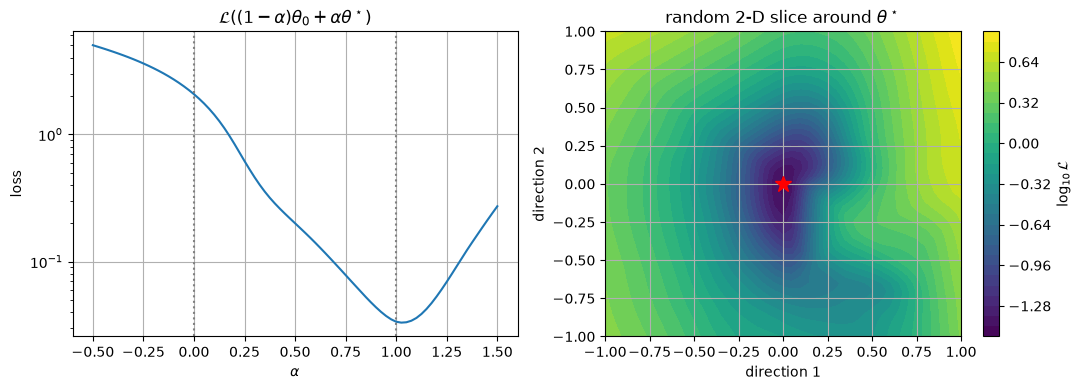

In [3]:
Xm, ym = make_moons(n_samples=400, noise=0.15, random_state=0)
r = np.random.default_rng(0)
theta0 = init_mlp([2, 32, 32, 2], r)
theta = [p.copy() for p in theta0]
for epoch in range(300):                                   # plain full-batch GD
    loss, grads = mlp_loss_grad(theta, Xm, ym)
    theta = [p - 0.5 * g for p, g in zip(theta, grads)]
print(f"trained MLP: loss {loss:.4f}, accuracy {np.mean(mlp_predict(theta, Xm) == ym):.3f}")

alphas = np.linspace(-0.5, 1.5, 81)
interp = [mlp_loss_grad([(1 - a) * p0 + a * p1 for p0, p1 in zip(theta0, theta)], Xm, ym)[0] for a in alphas]

def random_direction(params, rng):
    d = [rng.normal(size=p.shape) for p in params]
    return [di * np.linalg.norm(p) / np.linalg.norm(di) if p.ndim > 1 else 0 * di
            for di, p in zip(d, params)]

d1, d2 = random_direction(theta, r), random_direction(theta, r)
span = np.linspace(-1, 1, 41)
surface = np.array([[mlp_loss_grad([p + a * u + b * v for p, u, v in zip(theta, d1, d2)], Xm, ym)[0]
                     for a in span] for b in span])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(alphas, interp); axes[0].axvline(0, c="gray", ls=":"); axes[0].axvline(1, c="gray", ls=":")
axes[0].set_xlabel(r"$\alpha$"); axes[0].set_ylabel("loss"); axes[0].set_yscale("log")
axes[0].set_title(r"$\mathcal{L}((1-\alpha)\theta_0 + \alpha\theta^\star)$")
cs = axes[1].contourf(span, span, np.log10(surface), levels=30, cmap="viridis")
axes[1].plot(0, 0, "r*", ms=12); plt.colorbar(cs, ax=axes[1], label=r"$\log_{10}\mathcal{L}$")
axes[1].set_xlabel("direction 1"); axes[1].set_ylabel("direction 2"); axes[1].set_title("random 2-D slice around $\\theta^\\star$")
plt.tight_layout(); plt.show()

Such pictures are surprisingly benign: the interpolation path decreases almost
monotonically, and around the minimum the slice looks like a (skewed) bowl. Of
course these are 1-D and 2-D slices of a very high-dimensional function, so they
can hide a lot. Two facts that *are* well established:

* In high dimensions, most critical points with high loss are **saddle points**
  rather than local minima (Dauphin et al., 2014): for a minimum *every* one of the
  $p$ curvature directions must curve upwards.
* Locally, any smooth loss looks like a **quadratic**,
  $\mathcal L(\theta^\star+\boldsymbol\delta)\approx\mathcal L(\theta^\star)+\tfrac12\boldsymbol\delta^\top H\boldsymbol\delta$,
  where $H$ is the Hessian. Understanding gradient descent on quadratics therefore
  explains much of what happens near a minimum.

## 2. Gradient descent on a quadratic

Take $\mathcal L(\mathbf w) = \tfrac12\mathbf w^\top A\mathbf w$ with $A$ symmetric positive definite, eigenvalues
$0<\lambda_\text{min}\le\dots\le\lambda_\text{max}$ and eigenvectors $\mathbf u_i$. Gradient descent
$\mathbf w_{t+1} = \mathbf w_t - \eta A\mathbf w_t = (I-\eta A)\mathbf w_t$ decouples in the eigenbasis:

$$ \mathbf u_i^\top\mathbf w_t = (1-\eta\lambda_i)^t\,\mathbf u_i^\top\mathbf w_0 . $$

Consequences:

* **Stability:** we need $|1-\eta\lambda_i|<1$ for all $i$, i.e. $\eta < 2/\lambda_\text{max}$.
  The *sharpest* direction limits the step size.
* **Speed:** with $\eta < 2/\lambda_\text{max}$, the *flattest* direction converges with factor
  $1-\eta\lambda_\text{min}$ per step. The best fixed step $\eta^\star = 2/(\lambda_\text{min}+\lambda_\text{max})$ gives
  the rate
  $$ \max_i|1-\eta^\star\lambda_i| = \frac{\kappa-1}{\kappa+1},\qquad \kappa = \frac{\lambda_\text{max}}{\lambda_\text{min}} \ \text{(condition number)}. $$
  For $\kappa=100$ that is $0.98$ per step: about $\kappa/2\cdot\ln 10 \approx 115$ steps per digit of accuracy.
* In between, oscillation: for $1/\lambda_i<\eta<2/\lambda_i$ the factor is negative and
  the iterate zig-zags across the valley in direction $\mathbf u_i$.

Let us see this on $A=\operatorname{diag}(1, \kappa)$ with $\kappa = 10$.

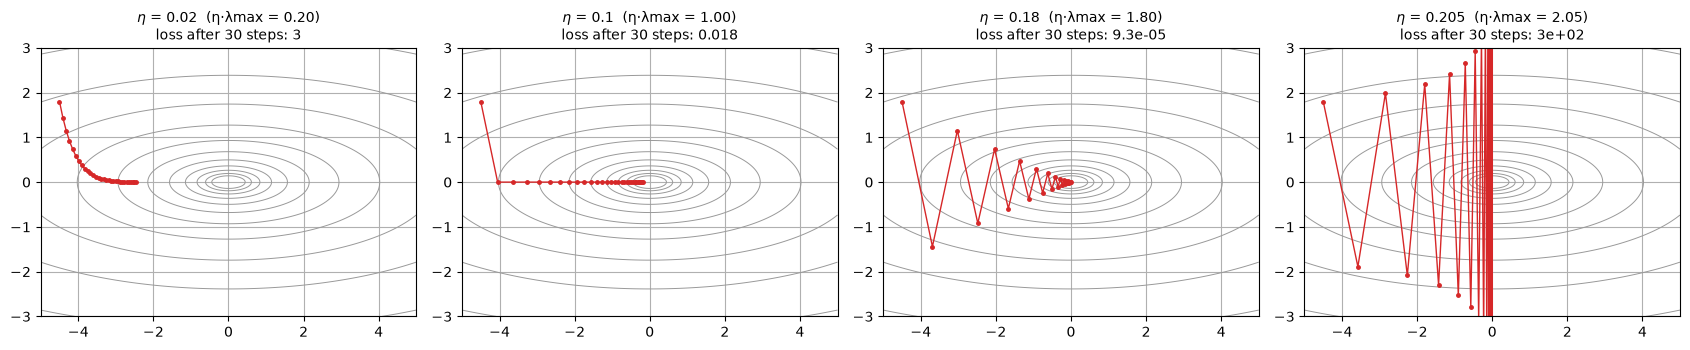

In [4]:
def run_optimizer(update, grad_fn, w0, steps):
    """Iterate w <- update(w, grad, state) and return the trajectory."""
    w, state, path = np.array(w0, float), {}, [np.array(w0, float)]
    for t in range(1, steps + 1):
        w = update(w, grad_fn(w), state, t)
        path.append(w.copy())
        if not np.all(np.isfinite(w)) or np.abs(w).max() > 1e6:
            break
    return np.array(path)


def gd(lr):
    return lambda w, g, s, t: w - lr * g


kappa = 10.0
A = np.diag([1.0, kappa])
quad = lambda W: 0.5 * np.einsum("...i,ij,...j->...", W, A, W)
quad_grad = lambda w: A @ w
w_start = np.array([-4.5, 1.8])

g1, g2 = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-3, 3, 200))
Q = quad(np.stack([g1, g2], -1))

def plot_path(ax, path, **kw):
    ax.plot(path[:, 0], path[:, 1], "o-", ms=2.5, lw=1, **kw)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, lr in zip(axes, [0.02, 0.1, 0.18, 0.205]):
    ax.contour(g1, g2, Q, levels=np.logspace(-1, 2, 12), colors="0.6", linewidths=0.7)
    path = run_optimizer(gd(lr), quad_grad, w_start, 30)
    plot_path(ax, path, c="C3")
    ax.set_xlim(-5, 5); ax.set_ylim(-3, 3)
    ax.set_title(f"$\\eta$ = {lr}  (η·λmax = {lr * kappa:.2f})\nloss after 30 steps: {quad(path[-1]):.2g}", fontsize=10)
plt.tight_layout(); plt.show()

* $\eta = 0.02$: stable but painfully slow along the flat $w_1$ axis.
* $\eta = 0.1 = 1/\lambda_\text{max}$: the steep direction is solved in one step; the flat one is still slow.
* $\eta = 0.18$: close to the limit, the iterate zig-zags across the valley.
* $\eta = 0.205 > 2/\lambda_\text{max}$: divergence along the steep direction.

The learning rate is a compromise between the steepest and the flattest direction,
and the condition number measures how bad that compromise is. Neural-network losses
are typically very ill-conditioned (the Hessian spectrum spans many orders of
magnitude), which motivates all the methods below.

### 2.1 The Rosenbrock function

A classic non-convex test problem is the Rosenbrock "banana"

$$ f(x, y) = (1-x)^2 + 100\,(y-x^2)^2 , $$

with its global minimum at $(1,1)$ at the bottom of a long, narrow, curved valley.
The curvature across the valley is about $200(1+4x^2)$, along it of order $1$: a
condition number in the hundreds or thousands that *changes as we move*.

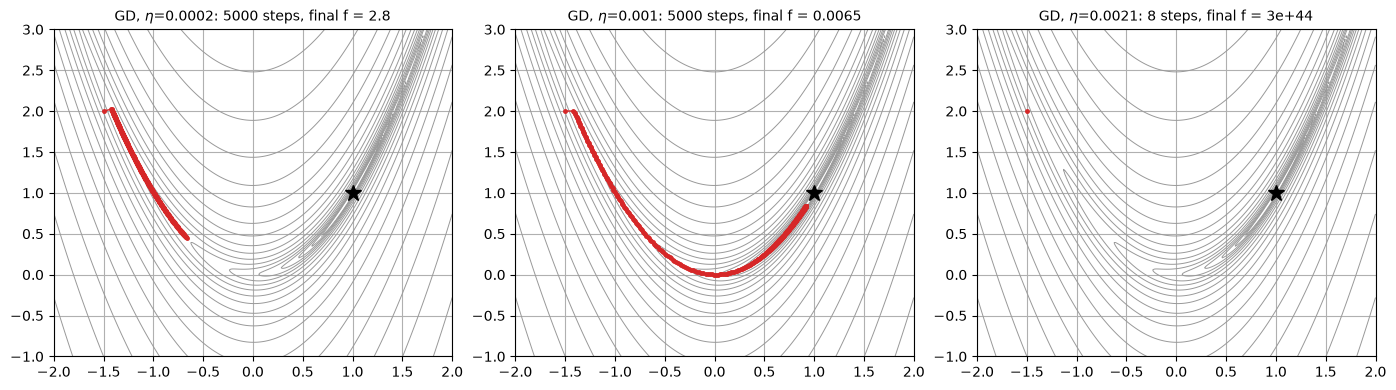

In [5]:
def rosen(x, y):
    return (1 - x) ** 2 + 100 * (y - x ** 2) ** 2

def rosen_grad(w):
    x, y = w
    return np.array([-2 * (1 - x) - 400 * x * (y - x ** 2), 200 * (y - x ** 2)])

r1, r2 = np.meshgrid(np.linspace(-2, 2, 300), np.linspace(-1, 3, 300))
R = rosen(r1, r2)
r_start = np.array([-1.5, 2.0])

def rosen_axes(ax, title):
    ax.contour(r1, r2, R, levels=np.logspace(-1, 3.5, 20), colors="0.6", linewidths=0.7)
    ax.plot(1, 1, "k*", ms=12)
    ax.set_xlim(-2, 2); ax.set_ylim(-1, 3); ax.set_title(title, fontsize=10)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, lr in zip(axes, [2e-4, 1e-3, 2.1e-3]):
    path = run_optimizer(gd(lr), rosen_grad, r_start, 5000)
    rosen_axes(ax, f"GD, $\\eta$={lr}: {len(path) - 1} steps, final f = {rosen(*path[-1]):.2g}")
    plot_path(ax, path[::10], c="C3")
plt.tight_layout(); plt.show()

With a small step GD crawls down to the valley floor and then barely moves along it;
with a larger one it makes progress along the valley but starts to oscillate across
it, and a little larger still it diverges (the sharp curvature at the starting
point: the largest Hessian eigenvalue there is $\approx 1900$, so stability requires
$\eta \lesssim 2/1900 \approx 1.05\times10^{-3}$. The middle run sits just below this limit;
the right one is twice as large and blows up within a few steps).

## 3. Full-batch, stochastic and mini-batch gradient descent

The training loss is an average, $\mathcal L(\theta) = \frac1N\sum_{i=1}^N\ell_i(\theta)$. Instead of
the full gradient we can use the gradient on a random **mini-batch** $\mathcal B$ of size $B$:

$$ \mathbf g_\mathcal B = \frac1B\sum_{i\in\mathcal B}\nabla\ell_i(\theta), \qquad
\mathbb E[\mathbf g_\mathcal B] = \nabla\mathcal L(\theta), \qquad
\operatorname{Cov}[\mathbf g_\mathcal B] \approx \frac{1}{B}\,\Sigma(\theta), $$

where $\Sigma$ is the covariance of the per-example gradients (for sampling with
replacement; without replacement there is an extra factor $\frac{N-B}{N-1}$).
So the mini-batch gradient is an **unbiased but noisy** estimate whose standard
deviation falls only like $1/\sqrt B$. The trade-off:

* the cost of a step is proportional to $B$, but the noise only falls like $1/\sqrt B$ —
  so per example processed, small batches make much more progress early on;
* near a minimum the noise does not vanish, so SGD with a constant learning rate
  **bounces around** in a region whose size scales with $\eta/B$ — we need to decay
  the learning rate (Section 6) or grow the batch;
* large batches use parallel hardware efficiently, which is why in practice $B$ is
  chosen as large as the hardware allows, with $\eta$ scaled up accordingly.

We illustrate this with linear regression in two parameters, where we can draw
the whole landscape.

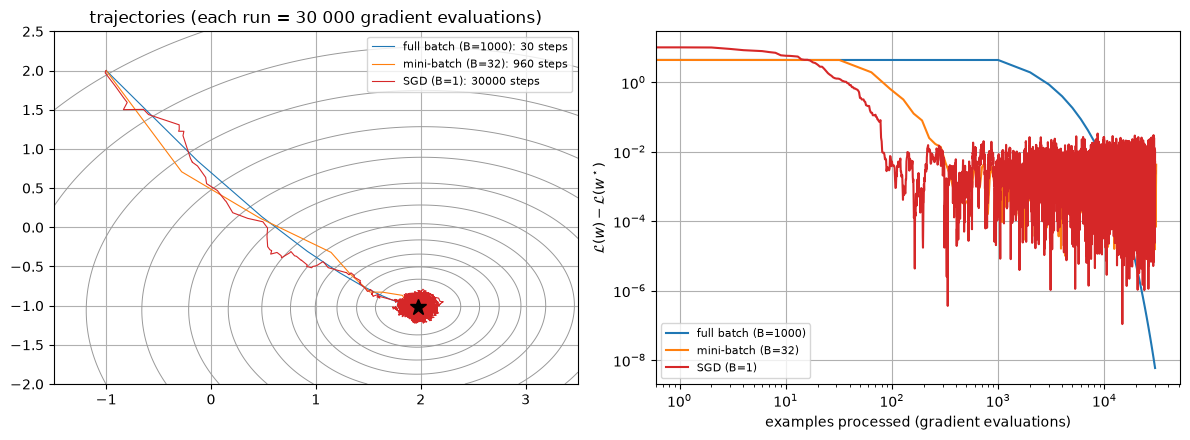

In [6]:
r = np.random.default_rng(0)
N = 1000
X_lr = np.c_[r.normal(size=N), r.normal(size=N) * 0.5 + 1]     # correlated with the intercept-like feature
w_true = np.array([2.0, -1.0])
y_lr = X_lr @ w_true + 0.5 * r.normal(size=N)
w_opt = np.linalg.lstsq(X_lr, y_lr, rcond=None)[0]

def lr_loss(w):
    return 0.5 * np.mean((X_lr @ w - y_lr) ** 2)

def lr_grad(w, idx=slice(None)):
    Xb = X_lr[idx]
    return Xb.T @ (Xb @ w - y_lr[idx]) / len(Xb)

def sgd_path(B, lr, epochs, seed=0):
    rr = np.random.default_rng(seed)
    w, path = np.array([-1.0, 2.0]), [np.array([-1.0, 2.0])]
    for _ in range(epochs):
        idx = rr.permutation(N)
        for s in range(0, N, B):
            w = w - lr * lr_grad(w, idx[s:s + B])
            path.append(w.copy())
    return np.array(path)

paths = {"full batch (B=1000)": sgd_path(1000, 0.3, 30),     # 30 epochs each:
         "mini-batch (B=32)": sgd_path(32, 0.3, 30),        # the same number of
         "SGD (B=1)": sgd_path(1, 0.03, 30)}                # gradient evaluations

a1, a2 = np.meshgrid(np.linspace(-1.5, 3.5, 150), np.linspace(-2, 2.5, 150))
LL = np.array([lr_loss(np.array([u, v])) for u, v in zip(a1.ravel(), a2.ravel())]).reshape(a1.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].contour(a1, a2, LL, levels=np.logspace(-0.7, 1, 12), colors="0.6", linewidths=0.7)
for (name, p), c in zip(paths.items(), ["C0", "C1", "C3"]):
    axes[0].plot(p[:, 0], p[:, 1], "-", lw=0.8, c=c, label=f"{name}: {len(p) - 1} steps")
axes[0].plot(*w_opt, "k*", ms=12); axes[0].legend(fontsize=8); axes[0].set_title("trajectories (each run = 30 000 gradient evaluations)")
for (name, p), c, B in zip(paths.items(), ["C0", "C1", "C3"], [1000, 32, 1]):
    seen = np.arange(len(p)) * B
    axes[1].plot(seen, [lr_loss(w) - lr_loss(w_opt) for w in p], c=c, label=name)
axes[1].set_yscale("log"); axes[1].set_xscale("log"); axes[1].set_xlabel("examples processed (gradient evaluations)")
axes[1].set_ylabel(r"$\mathcal{L}(w) - \mathcal{L}(w^\star)$"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

Per example processed, SGD and small mini-batches get close to the optimum far
faster than full-batch GD — but they then hover in a noisy ball around it, while
full-batch GD converges steadily. (SGD needs a smaller $\eta$ here: a single example's
gradient can be large.) The noise level really does scale like $1/B$:

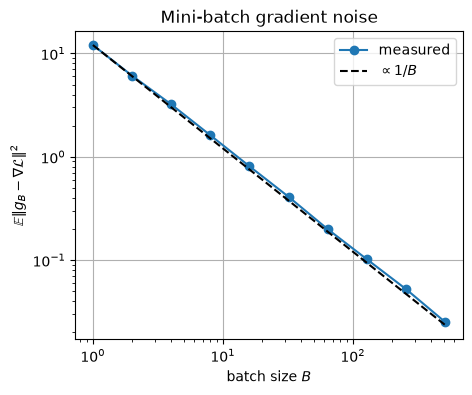

In [7]:
w_probe = np.array([0.5, 0.5])
full = lr_grad(w_probe)
Bs = 2 ** np.arange(0, 10)
var = []
for B in Bs:
    G = np.array([lr_grad(w_probe, r.choice(N, B, replace=True)) for _ in range(2000)])
    var.append(np.mean(np.sum((G - full) ** 2, axis=1)))
plt.loglog(Bs, var, "o-", label="measured")
plt.loglog(Bs, var[0] / Bs, "k--", label=r"$\propto 1/B$")
plt.xlabel("batch size $B$"); plt.ylabel(r"$\mathbb{E}\|g_B - \nabla\mathcal{L}\|^2$")
plt.legend(); plt.title("Mini-batch gradient noise"); plt.show()

The gradient noise is not only a nuisance: it helps escape saddle points and is
believed to bias SGD towards "flat" minima that generalise well (Keskar et al., 2017;
Smith & Le, 2018) — a topic we return to in the regularisation lecture.

## 4. Momentum

GD zig-zags across narrow valleys because the gradient points mostly *across* the
valley. **Momentum** (Polyak's heavy ball, 1964) accumulates an exponentially decaying
sum of past gradients, a "velocity":

$$ \mathbf v_{t} = \mu\,\mathbf v_{t-1} + \mathbf g_t, \qquad \theta_{t} = \theta_{t-1} - \eta\,\mathbf v_{t}, \qquad \mu\in[0,1). $$

Unrolling, $\mathbf v_t = \sum_{k\ge0}\mu^k\mathbf g_{t-k}$. Components of the gradient that
keep the same sign (along the valley) add up, to an effective step of
$\eta/(1-\mu)$ — $10\times$ larger for $\mu = 0.9$ — while components that alternate
in sign (across the valley) cancel. It is the discretisation of a ball with mass
rolling under friction, $\ddot\theta + c\,\dot\theta = -\nabla\mathcal L$.

On a quadratic, with optimally tuned $\eta$ and $\mu$, heavy ball converges at the rate
$\frac{\sqrt\kappa-1}{\sqrt\kappa+1}$ instead of $\frac{\kappa-1}{\kappa+1}$: for $\kappa=100$, $0.82$ instead of
$0.98$ per step — an order of magnitude fewer steps.

**Nesterov's accelerated gradient** (1983; in this form Sutskever et al., 2013)
evaluates the gradient at the "look-ahead" point where momentum is about to take us:

$$ \mathbf v_t = \mu\,\mathbf v_{t-1} + \nabla\mathcal L(\theta_{t-1} - \eta\mu\,\mathbf v_{t-1}), \qquad \theta_t = \theta_{t-1} - \eta\,\mathbf v_t . $$

If the velocity is about to overshoot, the look-ahead gradient already points back
and brakes earlier, damping the oscillations. Nesterov's method is optimal among
first-order methods for smooth convex functions. In deep-learning libraries it is
usually implemented in an equivalent form that only needs the gradient at the current
point: $\mathbf v_t = \mu\mathbf v_{t-1} + \mathbf g_t$, $\theta_t = \theta_{t-1} - \eta(\mathbf g_t + \mu\mathbf v_t)$.

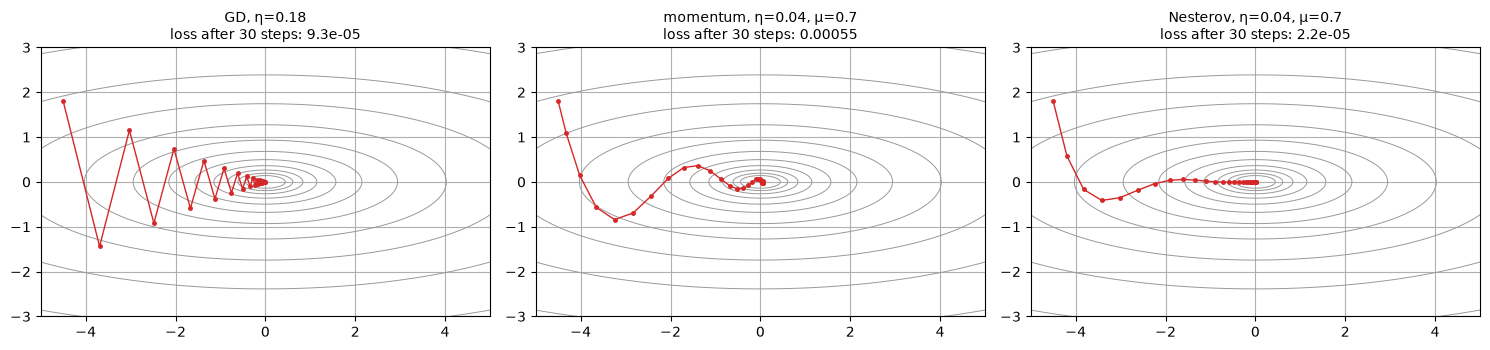

In [8]:
def momentum(lr, mu=0.9, nesterov=False):
    def update(w, g, s, t):
        v = s.get("v", np.zeros_like(w))
        v = mu * v + g
        s["v"] = v
        return w - lr * (g + mu * v if nesterov else v)
    return update

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (name, upd) in zip(axes, [("GD, η=0.18", gd(0.18)),
                                   ("momentum, η=0.04, μ=0.7", momentum(0.04, 0.7)),
                                   ("Nesterov, η=0.04, μ=0.7", momentum(0.04, 0.7, nesterov=True))]):
    ax.contour(g1, g2, Q, levels=np.logspace(-1, 2, 12), colors="0.6", linewidths=0.7)
    path = run_optimizer(upd, quad_grad, w_start, 30)
    plot_path(ax, path, c="C3"); ax.set_xlim(-5, 5); ax.set_ylim(-3, 3)
    ax.set_title(f"{name}\nloss after 30 steps: {quad(path[-1]):.2g}", fontsize=10)
plt.tight_layout(); plt.show()

On the quadratic, momentum overshoots along the flat axis (the "ball" carries
speed past the minimum) but still converges much faster than GD; Nesterov's
look-ahead removes most of the overshoot. On Rosenbrock, GD is already at its
stability limit and cannot go faster; momentum with a *smaller* $\eta$ but an effective
step $\eta/(1-\mu) = 4\times10^{-3}$ along the valley gets much closer to the minimum in the
same number of steps:

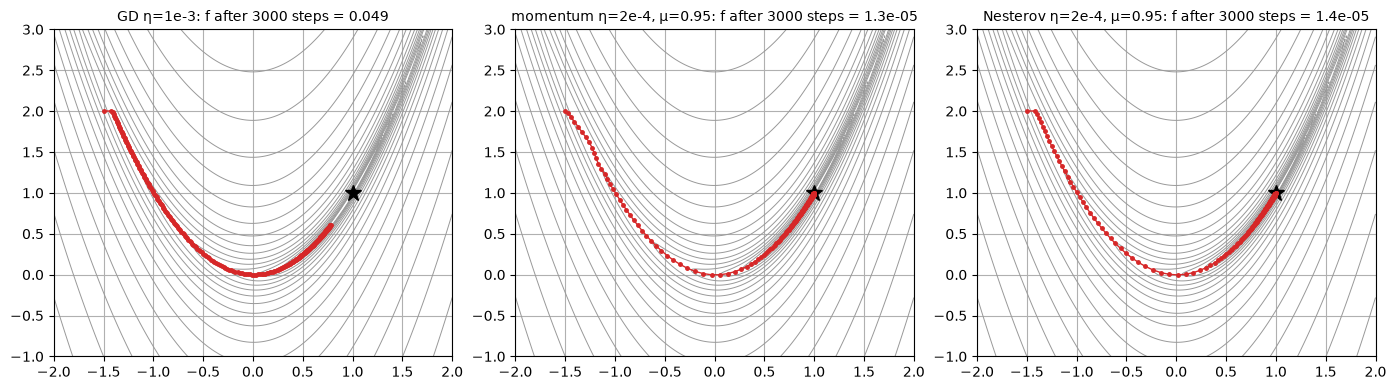

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, upd) in zip(axes, [("GD η=1e-3", gd(1e-3)), ("momentum η=2e-4, μ=0.95", momentum(2e-4, 0.95)),
                                   ("Nesterov η=2e-4, μ=0.95", momentum(2e-4, 0.95, nesterov=True))]):
    path = run_optimizer(upd, rosen_grad, r_start, 3000)
    rosen_axes(ax, f"{name}: f after 3000 steps = {rosen(*path[-1]):.2g}")
    plot_path(ax, path[::10], c="C3")
plt.tight_layout(); plt.show()

## 5. Adaptive learning rates: AdaGrad, RMSProp, Adam

Momentum still uses *one* learning rate for all parameters. But parameters differ:
the curvature along different directions spans orders of magnitude, some features
are rare (their weights receive few, large gradients), and parameters in different
layers have different scales. **Adaptive** methods give every parameter its own step
size based on the history of its gradients. All operations below are **elementwise**.

**AdaGrad** (Duchi, Hazan & Singer, 2011) divides by the root of the *sum* of all past squared gradients:

$$ \mathbf s_t = \mathbf s_{t-1} + \mathbf g_t^2, \qquad \theta_t = \theta_{t-1} - \eta\,\frac{\mathbf g_t}{\sqrt{\mathbf s_t}+\epsilon} . $$

Parameters with large gradients get smaller steps and vice versa. Good for convex
problems with sparse features, but $\mathbf s_t$ only grows, so the effective step size
decays like $1/\sqrt t$ and training eventually stalls.

**RMSProp** (Hinton, 2012, lecture notes) replaces the sum by an exponential moving average,
so the method "forgets" the distant past:

$$ \mathbf s_t = \rho\,\mathbf s_{t-1} + (1-\rho)\,\mathbf g_t^2, \qquad \theta_t = \theta_{t-1} - \eta\,\frac{\mathbf g_t}{\sqrt{\mathbf s_t}+\epsilon}, \qquad \rho\approx 0.9\text{–}0.99. $$

$\sqrt{\mathbf s_t}$ estimates the root-mean-square gradient of each parameter, so the update
$\mathbf g/\mathrm{RMS}(\mathbf g)$ has magnitude $\approx 1$ regardless of the gradient's scale: the step
size is $\approx\eta$ *in parameter space*. This is a crude diagonal approximation to the
curvature.

**Adam** (Kingma & Ba, 2015) combines momentum (a moving average of $\mathbf g$, the
"first moment") with RMSProp (a moving average of $\mathbf g^2$, the "second moment"):

$$
\begin{aligned}
\mathbf m_t &= \beta_1\mathbf m_{t-1} + (1-\beta_1)\,\mathbf g_t, &\qquad
\hat{\mathbf m}_t &= \frac{\mathbf m_t}{1-\beta_1^t},\\
\mathbf v_t &= \beta_2\mathbf v_{t-1} + (1-\beta_2)\,\mathbf g_t^2, &\qquad
\hat{\mathbf v}_t &= \frac{\mathbf v_t}{1-\beta_2^t},\\
\theta_t &= \theta_{t-1} - \eta\,\frac{\hat{\mathbf m}_t}{\sqrt{\hat{\mathbf v}_t}+\epsilon}, &&
\end{aligned}
$$

with defaults $\beta_1=0.9$, $\beta_2=0.999$, $\epsilon=10^{-8}$, and typically $\eta \approx 10^{-3}$.

### 5.1 Why bias correction?

Both moving averages start at $\mathbf m_0 = \mathbf v_0 = \mathbf 0$. Unrolling the recursion,

$$ \mathbf m_t = (1-\beta_1)\sum_{k=1}^{t}\beta_1^{t-k}\,\mathbf g_k . $$

If the gradients are stationary with $\mathbb E[\mathbf g_k] = \mathbf g$, then

$$ \mathbb E[\mathbf m_t] = (1-\beta_1)\,\mathbf g\sum_{k=1}^{t}\beta_1^{t-k} = (1-\beta_1)\,\frac{1-\beta_1^t}{1-\beta_1}\,\mathbf g = (1-\beta_1^t)\,\mathbf g . $$

The average is **biased towards zero** by exactly the factor $1-\beta_1^t$ — the weight that
the missing pre-history ($k\le0$) would have had. Dividing by $1-\beta_1^t$ removes the bias;
the same argument gives $\mathbb E[\mathbf v_t] = (1-\beta_2^t)\,\mathbb E[\mathbf g^2]$.

The correction matters most for $\mathbf v$: with $\beta_2 = 0.999$, after $t=10$ steps
$1-\beta_2^{t} \approx 0.01$, so the uncorrected $\sqrt{\mathbf v_t}$ would be about $10\times$ too small
while $\mathbf m_t$ is already ~65 % of its final scale — the very first updates would be
roughly $6\times$ too large. For large $t$ both factors tend to $1$ and the correction has no effect.

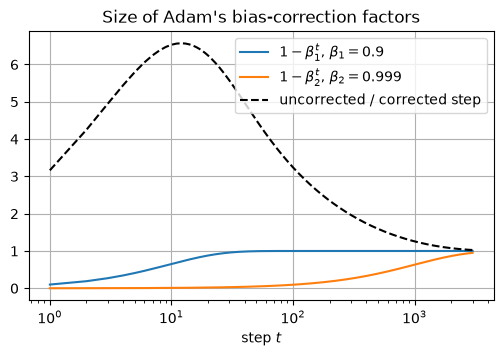

In [10]:
t = np.arange(1, 3001)
plt.figure(figsize=(6, 3.5))
plt.semilogx(t, 1 - 0.9 ** t, label=r"$1-\beta_1^t$, $\beta_1=0.9$")
plt.semilogx(t, 1 - 0.999 ** t, label=r"$1-\beta_2^t$, $\beta_2=0.999$")
plt.semilogx(t, (1 - 0.9 ** t) / np.sqrt(1 - 0.999 ** t), "k--", label="uncorrected / corrected step")
plt.xlabel("step $t$"); plt.legend(); plt.title("Size of Adam's bias-correction factors"); plt.show()

Here are the three methods as update rules, and a comparison on both test functions.
Note how the adaptive methods take steps of roughly constant size $\eta$ (they move
"diagonally" at first because both coordinates get the same normalised step size).

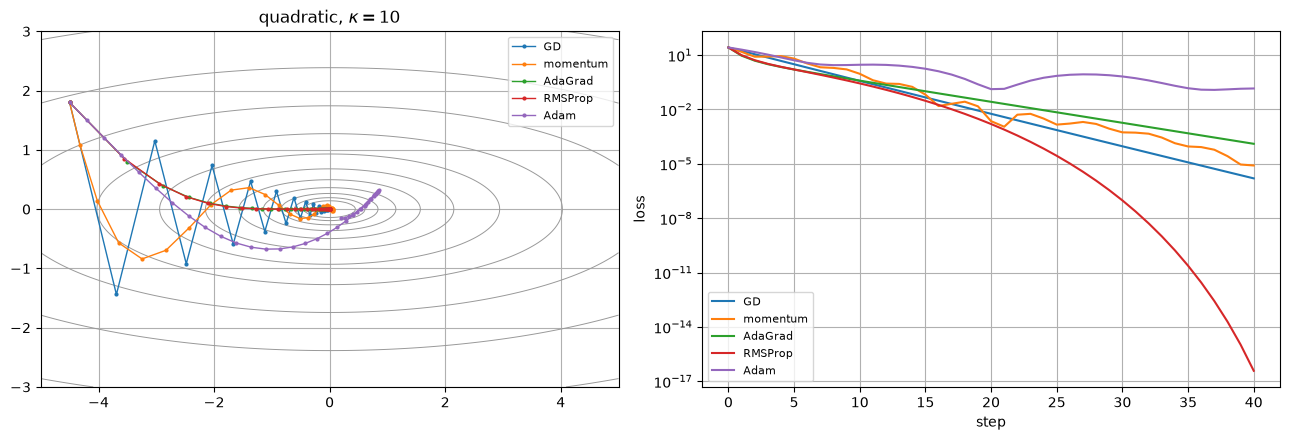

In [11]:
def adagrad(lr, eps=1e-8):
    def update(w, g, s, t):
        s["s"] = s.get("s", 0) + g ** 2
        return w - lr * g / (np.sqrt(s["s"]) + eps)
    return update

def rmsprop(lr, rho=0.9, eps=1e-8):
    def update(w, g, s, t):
        s["s"] = rho * s.get("s", 0) + (1 - rho) * g ** 2
        return w - lr * g / (np.sqrt(s["s"]) + eps)
    return update

def adam(lr, b1=0.9, b2=0.999, eps=1e-8):
    def update(w, g, s, t):
        s["m"] = b1 * s.get("m", 0) + (1 - b1) * g
        s["v"] = b2 * s.get("v", 0) + (1 - b2) * g ** 2
        m_hat, v_hat = s["m"] / (1 - b1 ** t), s["v"] / (1 - b2 ** t)
        return w - lr * m_hat / (np.sqrt(v_hat) + eps)
    return update

methods = {"GD": gd(0.18), "momentum": momentum(0.04, 0.7), "AdaGrad": adagrad(1.0),
           "RMSProp": rmsprop(0.3), "Adam": adam(0.3)}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].contour(g1, g2, Q, levels=np.logspace(-1, 2, 12), colors="0.6", linewidths=0.7)
for name, upd in methods.items():
    p = run_optimizer(upd, quad_grad, w_start, 40)
    axes[0].plot(p[:, 0], p[:, 1], "o-", ms=2, lw=1, label=name)
    axes[1].semilogy([quad(w) for w in p], label=name)
axes[0].set_xlim(-5, 5); axes[0].set_ylim(-3, 3); axes[0].legend(fontsize=8); axes[0].set_title(r"quadratic, $\kappa=10$")
axes[1].set_xlabel("step"); axes[1].set_ylabel("loss"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

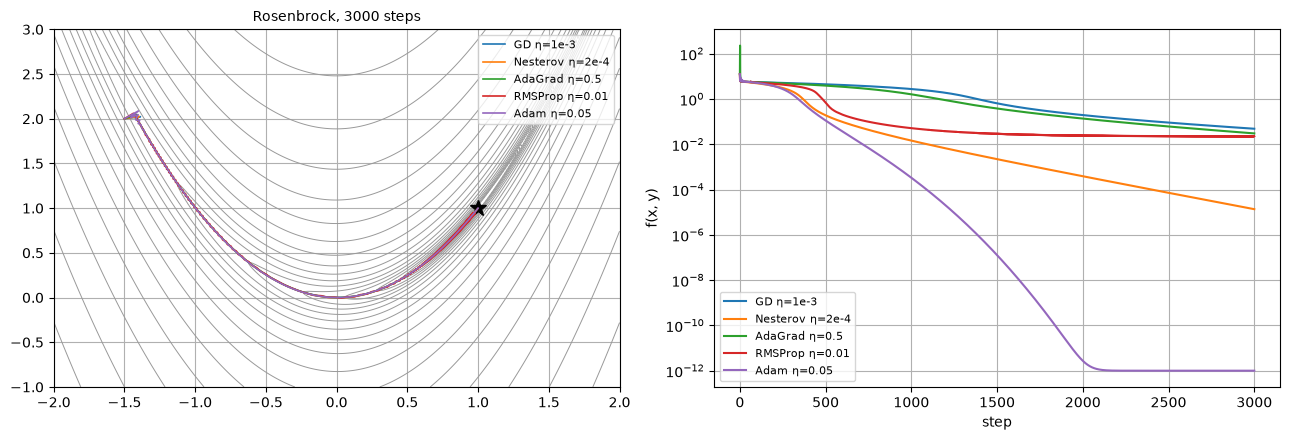

In [12]:
methods_r = {"GD η=1e-3": gd(1e-3), "Nesterov η=2e-4": momentum(2e-4, 0.95, nesterov=True),
             "AdaGrad η=0.5": adagrad(0.5), "RMSProp η=0.01": rmsprop(0.01), "Adam η=0.05": adam(0.05)}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rosen_axes(axes[0], "Rosenbrock, 3000 steps")
for name, upd in methods_r.items():
    p = run_optimizer(upd, rosen_grad, r_start, 3000)
    axes[0].plot(p[::5, 0], p[::5, 1], "-", lw=1.2, label=name)
    axes[1].semilogy([rosen(*w) + 1e-12 for w in p], label=name)
axes[0].legend(fontsize=8); axes[1].set_xlabel("step"); axes[1].set_ylabel("f(x, y)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

On the quadratic, RMSProp and AdaGrad essentially remove the ill-conditioning: after
normalisation both coordinates move at the same speed, so they head straight for the
minimum. Adam with its default $\beta_1 = 0.9$ carries a lot of momentum and orbits
around the minimum on this *deterministic* problem — its defaults are tuned for the
noisy gradients of deep learning, where the averaging is useful. On Rosenbrock, Adam is
by far the best of the five, because its per-coordinate normalisation adapts to the
changing curvature along the valley.

Low-dimensional test functions are useful for intuition but can be misleading: each
method's result depends strongly on its hyperparameters, and a 2-D picture has none
of the noise, scale and dimensionality of a real network. What matters is how the
methods behave on networks.

### 5.2 Optimisers on a real network

We wrap the update rules in a tiny optimiser interface acting on the list of
parameter arrays (exactly like `torch.optim`), and train a $64\to128\to128\to10$ ReLU
network on digits with each method, using a typical learning rate for each.

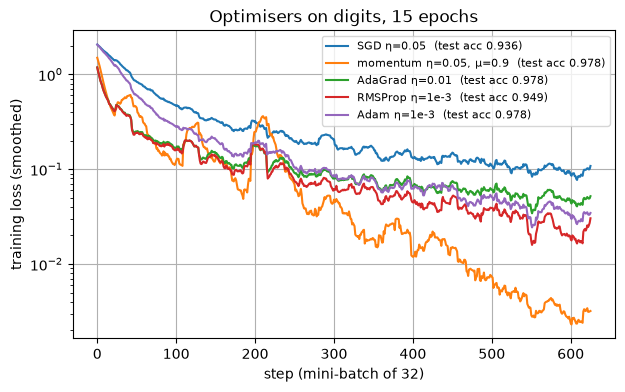

In [13]:
class Optimizer:
    """Applies an elementwise update rule to every parameter array, with separate state."""
    def __init__(self, params, rule):
        self.params, self.rule = params, rule
        self.state = [dict() for _ in params]
        self.t = 0
    def step(self, grads):
        self.t += 1
        for p, g, s in zip(self.params, grads, self.state):
            p[...] = self.rule(p, g, s, self.t)


digits = load_digits()
Xd, yd = digits.data / 16.0, digits.target
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.25, random_state=0, stratify=yd)


def train_mlp(rule, epochs=15, batch_size=32, seed=0, sizes=(64, 128, 128, 10), schedule=None, init="he"):
    r = np.random.default_rng(seed)
    params = init_mlp(list(sizes), r, init)
    opt = Optimizer(params, rule)
    losses, step = [], 0
    n_steps = epochs * int(np.ceil(len(Xd_tr) / batch_size))
    for _ in range(epochs):
        idx = r.permutation(len(Xd_tr))
        for s in range(0, len(Xd_tr), batch_size):
            j = idx[s:s + batch_size]
            loss, grads = mlp_loss_grad(params, Xd_tr[j], yd_tr[j])
            if schedule is not None:
                rule.lr = schedule(step, n_steps)
            opt.step(grads)
            losses.append(loss); step += 1
    return params, np.array(losses)


class Rule:
    """Update rules as callable objects with a mutable learning rate (for schedules)."""
    def __init__(self, kind, lr, **hp):
        self.kind, self.lr, self.hp = kind, lr, hp
    def __call__(self, w, g, s, t):
        return {"sgd": gd, "momentum": momentum, "adagrad": adagrad,
                "rmsprop": rmsprop, "adam": adam}[self.kind](self.lr, **self.hp)(w, g, s, t)


def smooth(x, k=20):
    return np.convolve(x, np.ones(k) / k, mode="valid")

configs = {"SGD η=0.05": Rule("sgd", 0.05), "momentum η=0.05, μ=0.9": Rule("momentum", 0.05, mu=0.9),
           "AdaGrad η=0.01": Rule("adagrad", 0.01), "RMSProp η=1e-3": Rule("rmsprop", 1e-3, rho=0.99),
           "Adam η=1e-3": Rule("adam", 1e-3)}
plt.figure(figsize=(7, 4))
for name, rule in configs.items():
    params, losses = train_mlp(rule)
    acc = np.mean(mlp_predict(params, Xd_te) == yd_te)
    plt.semilogy(smooth(losses), label=f"{name}  (test acc {acc:.3f})")
plt.xlabel("step (mini-batch of 32)"); plt.ylabel("training loss (smoothed)")
plt.legend(fontsize=8); plt.title("Optimisers on digits, 15 epochs"); plt.show()

All methods eventually work on this easy problem, but the plain SGD curve is clearly
slowest; momentum and the adaptive methods reach a low loss much faster. On large
problems the picture is similar: **Adam** (or its variant **AdamW**, which decouples
weight decay — see the regularisation lecture) is the default for transformers and
most new architectures because it works with little tuning; well-tuned **SGD with
momentum** remains competitive for convolutional networks and sometimes generalises
slightly better (Wilson et al., 2017).

## 6. Learning-rate schedules

Even with an adaptive method, $\eta$ should usually change during training:

* **large early** to make fast progress and to explore,
* **small late** to reduce the noise ball around the minimum (Section 3) and settle.

For SGD on convex problems, convergence to the minimum actually *requires* a decaying
step, e.g. the Robbins–Monro conditions $\sum_t\eta_t=\infty$, $\sum_t\eta_t^2<\infty$. Common schedules,
with $T$ the total number of steps:

| Schedule | $\eta_t$ |
|---|---|
| Step decay | $\eta_0\,\gamma^{\lfloor t/s\rfloor}$ (e.g. $\gamma=0.1$ every $s$ steps) |
| Exponential | $\eta_0\,\gamma^{t}$ |
| Cosine (Loshchilov & Hutter, 2017) | $\eta_\text{min} + \tfrac12(\eta_0-\eta_\text{min})\big(1+\cos(\pi t/T)\big)$ |
| Linear warm-up | $\eta_0\,t/T_\text{w}$ for $t<T_\text{w}$, then one of the above |

**Warm-up** starts with a tiny learning rate and increases it linearly over the first
few hundred or thousand steps (Goyal et al., 2017). At initialisation the gradients
can be large and erratic, Adam's second-moment estimates are based on very few
samples, and normalisation statistics are not yet settled; a large step at that point
can push the network into a bad region it never recovers from. Warm-up + cosine decay
is the standard recipe for training transformers.

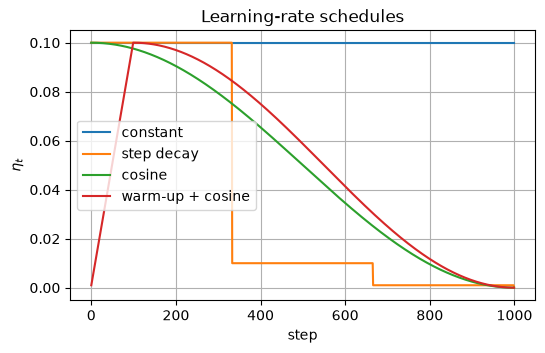

In [14]:
def step_decay(t, T, lr0=0.1, gamma=0.1, every=None):
    every = every or T // 3
    return lr0 * gamma ** (t // every)

def cosine(t, T, lr0=0.1, lr_min=0.0):
    return lr_min + 0.5 * (lr0 - lr_min) * (1 + np.cos(np.pi * t / T))

def warmup_cosine(t, T, lr0=0.1, warmup=None):
    warmup = warmup or T // 10
    if t < warmup:
        return lr0 * (t + 1) / warmup
    return cosine(t - warmup, T - warmup, lr0)

T = 1000
plt.figure(figsize=(6, 3.5))
for name, f in [("constant", lambda t, T: 0.1), ("step decay", step_decay), ("cosine", cosine),
                ("warm-up + cosine", warmup_cosine)]:
    plt.plot([f(t, T) for t in range(T)], label=name)
plt.xlabel("step"); plt.ylabel(r"$\eta_t$"); plt.legend(); plt.title("Learning-rate schedules"); plt.show()

We train the digits network with SGD + momentum and a deliberately *large* peak
learning rate, with and without schedules.

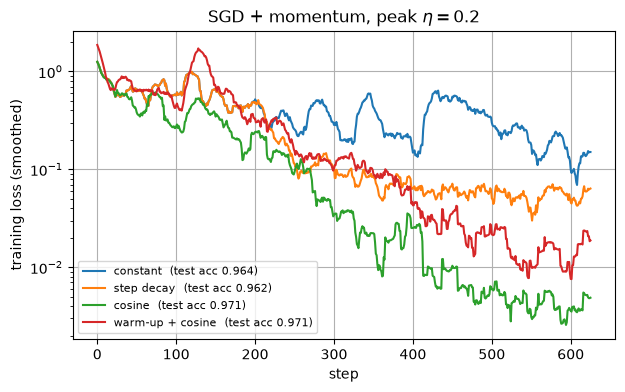

In [15]:
plt.figure(figsize=(7, 4))
for name, sched in [("constant", lambda t, T: 0.2), ("step decay", lambda t, T: step_decay(t, T, 0.2)),
                    ("cosine", lambda t, T: cosine(t, T, 0.2)),
                    ("warm-up + cosine", lambda t, T: warmup_cosine(t, T, 0.2))]:
    params, losses = train_mlp(Rule("momentum", 0.2, mu=0.9), epochs=15, schedule=sched)
    acc = np.mean(mlp_predict(params, Xd_te) == yd_te)
    plt.semilogy(smooth(losses), label=f"{name}  (test acc {acc:.3f})")
plt.xlabel("step"); plt.ylabel("training loss (smoothed)"); plt.legend(fontsize=8)
plt.title(r"SGD + momentum, peak $\eta = 0.2$"); plt.show()

With a constant large step the loss stays high and noisy; every decaying schedule
brings it down by more than an order of magnitude once the step size gets small, and
the final test accuracy is usually a little better too. The step schedule shows a
characteristic sudden drop in loss at each decay. On this small problem warm-up makes
little difference (the warm-up run is simply "behind" because it reaches the peak
learning rate later); it becomes essential for large models, large batches and
Adam-type optimisers, where an unlucky first few steps can make training diverge.

## 7. Weight initialisation

Where we start matters too. Two things must be avoided:

* **Symmetry.** If all weights of a layer are equal, all its units compute the same
  function and receive the same gradient — they stay identical forever. Weights must
  be initialised **randomly** (biases can be zero).
* **Vanishing/exploding signals.** In a deep network, the forward signal is multiplied
  by a weight matrix at every layer and the backward signal by its transpose. If each
  multiplication scales the signal by a factor $c$, after $L$ layers it is scaled by $c^L$:
  for $L = 20$ and $c = 0.8$ or $1.25$ that is $0.01$ or $87$.

### 7.1 The variance argument

Consider a layer $z_j = \sum_{i=1}^{n_\text{in}} W_{ij}h_i$ with weights i.i.d. with zero mean and
variance $\operatorname{Var}(W)$, independent of the inputs $h_i$, which are i.i.d. Then

$$ \operatorname{Var}(z_j) = \sum_{i=1}^{n_\text{in}}\operatorname{Var}(W_{ij}h_i) = n_\text{in}\,\operatorname{Var}(W)\;\mathbb E[h_i^2] $$

(using $\operatorname{Var}(WH) = \mathbb E[W^2]\mathbb E[H^2] - \mathbb E[W]^2\mathbb E[H]^2$ with $\mathbb E[W]=0$).

* **tanh** (Glorot & Bengio, 2010): near $0$, $\tanh z\approx z$, so $\mathbb E[h^2]\approx\operatorname{Var}(z^\text{prev})$.
  To keep $\operatorname{Var}(z)$ constant across layers we need $n_\text{in}\operatorname{Var}(W) = 1$.
  The same argument for the backward pass, $\bar h_i = \sum_j W_{ij}\bar z_j$, requires
  $n_\text{out}\operatorname{Var}(W)=1$. **Xavier/Glorot** initialisation compromises:
  $$\operatorname{Var}(W) = \frac{2}{n_\text{in}+n_\text{out}} .$$
* **ReLU** (He et al., 2015): if $z$ is symmetric around zero, $h = \max(0, z)$ satisfies
  $\mathbb E[h^2] = \tfrac12\operatorname{Var}(z)$ — half of the signal is zeroed. To compensate,
  **He/Kaiming** initialisation uses
  $$\operatorname{Var}(W) = \frac{2}{n_\text{in}} .$$

(For uniform distributions $U[-a,a]$, the variance is $a^2/3$; e.g. Glorot-uniform uses $a = \sqrt{6/(n_\text{in}+n_\text{out})}$.)

### 7.2 Experiment: activations in a deep network

We push 1 000 Gaussian inputs through a 10-layer network with 256 units per layer and
look at the distribution of the activations in every layer.

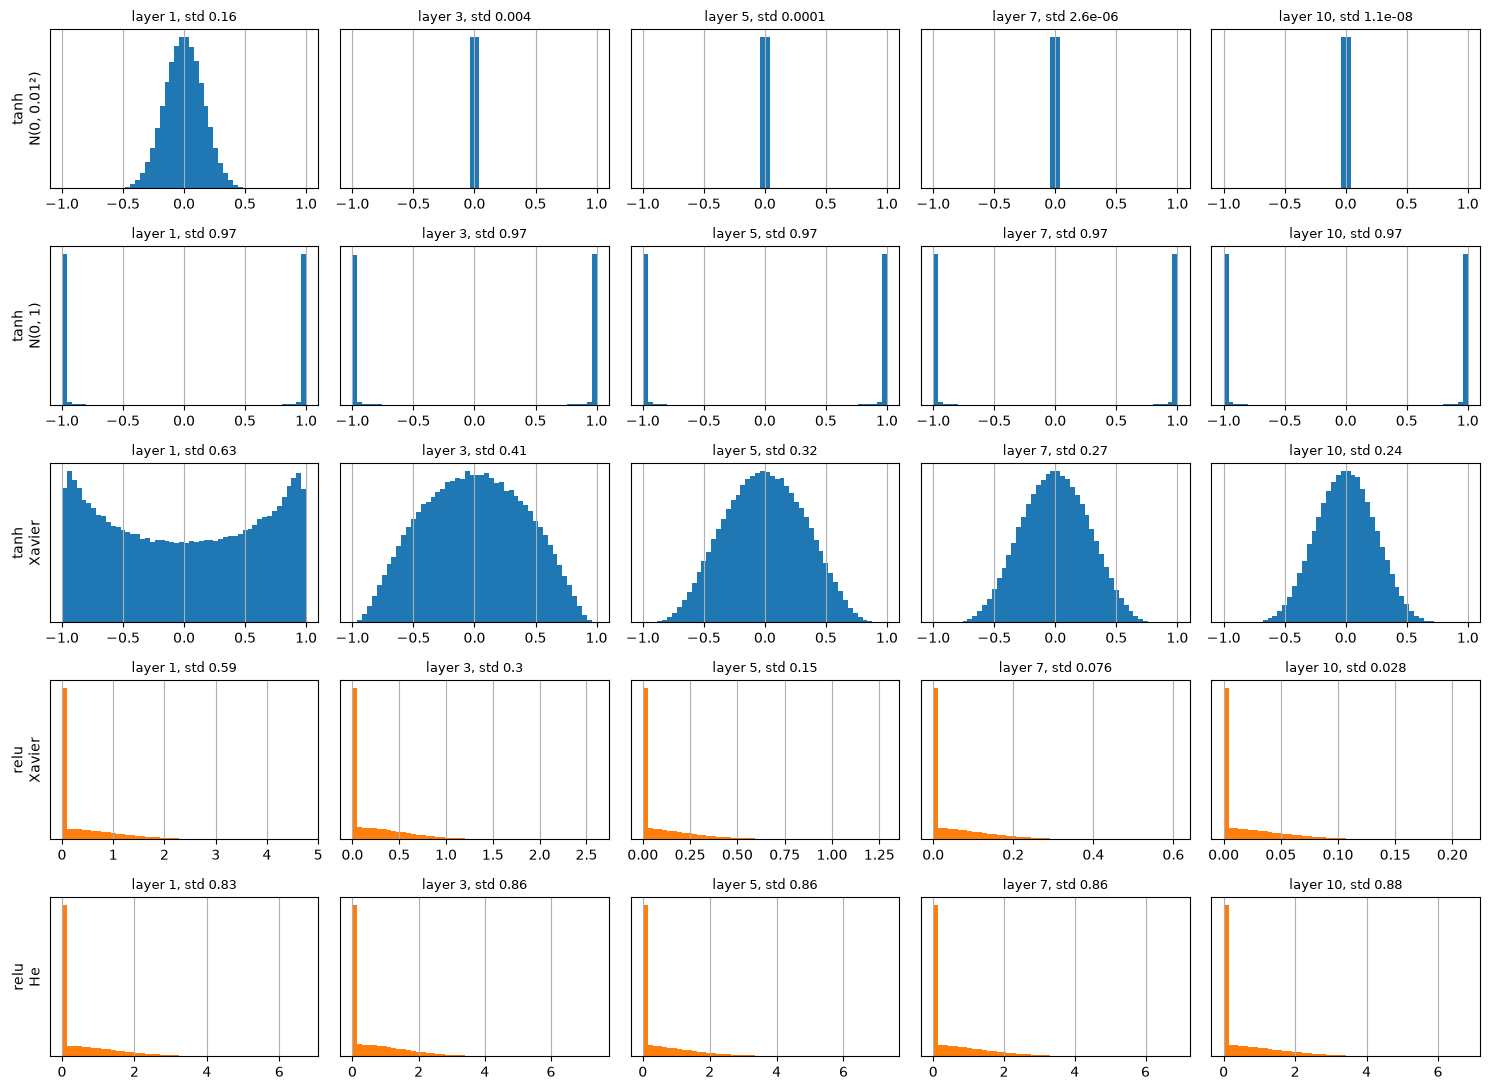

In [16]:
def forward_stats(act, std_fn, n_layers=10, width=256, seed=0):
    r = np.random.default_rng(seed)
    H = r.normal(size=(1000, width))
    f = np.tanh if act == "tanh" else (lambda z: np.maximum(z, 0))
    acts = []
    for _ in range(n_layers):
        W = r.normal(0, std_fn(width, width), size=(width, width))
        H = f(H @ W)
        acts.append(H)
    return acts

inits = [("tanh", "N(0, 0.01²)", lambda i, o: 0.01),
         ("tanh", "N(0, 1)", lambda i, o: 1.0),
         ("tanh", "Xavier", lambda i, o: np.sqrt(2 / (i + o))),
         ("relu", "Xavier", lambda i, o: np.sqrt(2 / (i + o))),
         ("relu", "He", lambda i, o: np.sqrt(2 / i))]

fig, axes = plt.subplots(len(inits), 5, figsize=(15, 2.2 * len(inits)))
for row, (act, name, std_fn) in enumerate(inits):
    acts = forward_stats(act, std_fn)
    for col, l in enumerate([0, 2, 4, 6, 9]):
        a = acts[l].ravel()
        rng_ = (-1, 1) if act == "tanh" else (0, max(a.max(), 1e-12))
        axes[row, col].hist(a, bins=50, range=rng_, color="C0" if act == "tanh" else "C1")
        axes[row, col].set_yticks([])
        axes[row, col].set_title(f"layer {l + 1}, std {a.std():.2g}", fontsize=9)
    axes[row, 0].set_ylabel(f"{act}\n{name}", fontsize=10)
plt.tight_layout(); plt.show()

* **tanh, tiny weights**: activations shrink by a factor $\approx 0.01\sqrt{256} = 0.16$ per layer
  and are essentially zero after a few layers. The gradients w.r.t. early weights are
  proportional to these activations, so they vanish too.
* **tanh, $\mathcal N(0,1)$**: pre-activations have std $\approx\sqrt{256}=16$, every unit is
  **saturated** at $\pm1$, and $\tanh'\approx 0$ — the backward signal vanishes.
* **tanh, Xavier**: the distribution stays healthy through all ten layers
  (it shrinks slowly because $\tanh$ is contracting for larger inputs).
* **ReLU, Xavier**: since half of the signal is cut off at each layer, the std
  decays by $\approx 1/\sqrt2$ per layer.
* **ReLU, He**: the factor 2 compensates exactly and the scale is preserved.

The same story holds for the gradients in the backward pass. Let us measure the
gradient norm of each layer's weights at initialisation in a 10-layer ReLU
network on digits, and how quickly the network trains.

N(0, 0.01²)  final training loss: 2.32


Xavier       final training loss: 0.441


He           final training loss: 0.00348


N(0, 0.2²)   final training loss: nan


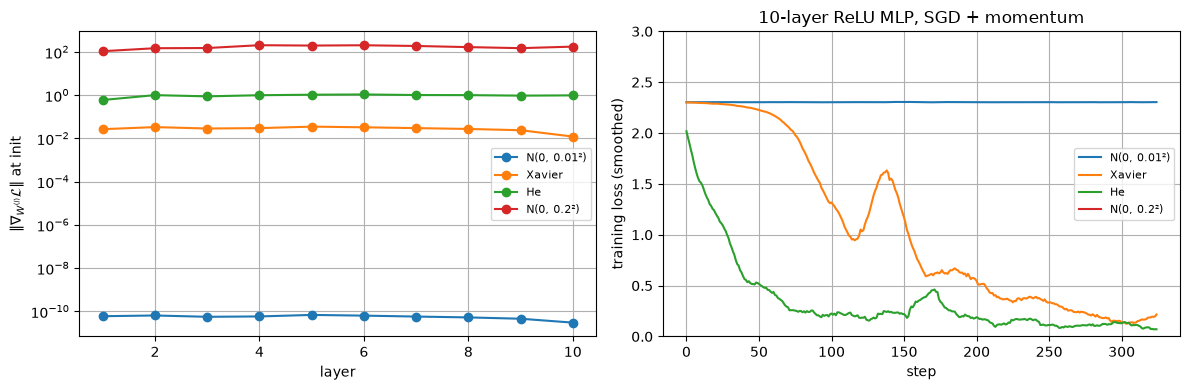

In [17]:
deep = [64] + [128] * 9 + [10]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, scale in [("N(0, 0.01²)", 0.01), ("Xavier", "xavier"), ("He", "he"), ("N(0, 0.2²)", 0.2)]:
    params = init_mlp(deep, np.random.default_rng(0), scale)
    _, grads = mlp_loss_grad(params, Xd_tr, yd_tr)
    axes[0].semilogy(range(1, len(deep)), [np.linalg.norm(g) for g in grads[0::2]], "o-", label=name)
    with np.errstate(all="ignore"):                       # the last run overflows
        _, losses = train_mlp(Rule("momentum", 0.01, mu=0.9), epochs=8, sizes=deep, init=scale)
    print(f"{name:12s} final training loss: {losses[-1]:.3g}")
    axes[1].plot(smooth(losses), label=name)
axes[0].set_xlabel("layer"); axes[0].set_ylabel(r"$\|\nabla_{W^{(l)}}\mathcal{L}\|$ at init"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("step"); axes[1].set_ylabel("training loss (smoothed)"); axes[1].set_ylim(0, 3)
axes[1].legend(fontsize=8); axes[1].set_title("10-layer ReLU MLP, SGD + momentum")
plt.tight_layout(); plt.show()

* With **tiny weights** every gradient is of order $10^{-10}$: the gradient of $W^{(l)}$ is the
  product of the forward signal $H^{(l-1)}$ (vanished in the early layers) and the
  backward signal $\delta^{(l)}$ (vanished in the late layers). The loss does not move at all.
* With **too-large weights** ($0.2 > \sqrt{2/128}\approx 0.125$) the signal grows by a factor
  $0.2/0.125 = 1.6$ per layer, the gradients are of order $10^2$, and training diverges
  immediately (the loss becomes NaN, so there is no curve).
* **Xavier** trains, but its gradients are about 30 times smaller than He's (a factor
  $\sqrt 2$ per layer, compounded) and it learns more slowly.
* **He** keeps the gradient norm roughly equal across layers and trains fastest.

Good initialisation is not the end of the story. Very deep networks additionally use
**normalisation layers** (batch/layer normalisation) and **residual connections**,
which keep signals well-scaled *during* training, not only at the start — both are
covered later in the course.

## Summary

| Topic | Key formula / idea |
|---|---|
| GD on a quadratic | stable iff $\eta<2/\lambda_\text{max}$; rate $\frac{\kappa-1}{\kappa+1}$ with $\kappa = \lambda_\text{max}/\lambda_\text{min}$ |
| Mini-batch SGD | unbiased gradient, noise variance $\propto 1/B$; constant $\eta$ ⇒ noise ball |
| Momentum | $\mathbf v\leftarrow\mu\mathbf v+\mathbf g$, $\theta\leftarrow\theta-\eta\mathbf v$; rate $\frac{\sqrt\kappa-1}{\sqrt\kappa+1}$ |
| Nesterov | gradient at the look-ahead point $\theta-\eta\mu\mathbf v$ |
| AdaGrad | $\mathbf s\leftarrow\mathbf s+\mathbf g^2$, step $\eta\,\mathbf g/\sqrt{\mathbf s}$ — decays like $1/\sqrt t$ |
| RMSProp | $\mathbf s\leftarrow\rho\mathbf s+(1-\rho)\mathbf g^2$, step $\eta\,\mathbf g/\sqrt{\mathbf s}$ |
| Adam | momentum + RMSProp + bias correction $\hat{\mathbf m}=\mathbf m/(1-\beta_1^t)$, $\hat{\mathbf v}=\mathbf v/(1-\beta_2^t)$ |
| Schedules | warm-up, then decay (step / cosine); large $\eta$ early, small late |
| Xavier/Glorot | $\operatorname{Var}(W)=2/(n_\text{in}+n_\text{out})$ — tanh, sigmoid, linear |
| He/Kaiming | $\operatorname{Var}(W)=2/n_\text{in}$ — ReLU |

**Practical defaults.** Adam(W) with $\eta\approx 10^{-3}$–$3\cdot10^{-4}$, or SGD with momentum $0.9$ and $\eta\approx0.1$
for (batch-normalised) CNNs; linear warm-up followed by cosine decay; He initialisation
for ReLU networks; and always plot the training loss — if it is NaN or flat, check
the learning rate first.

**Further reading.**
Goodfellow, Bengio & Courville, *Deep Learning*, ch. 8;
Bottou, Curtis & Nocedal (2018), "Optimization methods for large-scale machine learning", *SIAM Review*;
Goh (2017), "Why momentum really works", *Distill*;
Kingma & Ba (2015), "Adam: a method for stochastic optimization";
Glorot & Bengio (2010), "Understanding the difficulty of training deep feedforward neural networks";
He et al. (2015), "Delving deep into rectifiers";
Li et al. (2018), "Visualizing the loss landscape of neural nets";
Sebastian Ruder's blog post "An overview of gradient descent optimization algorithms".